# Data processing: synthetic and real pallet-jack images

This notebook is an interactive guide to how this project turns two different sources into detection-ready data. It explains each transformation, calls the reusable project code, and lets you inspect the labels visually.

**Synthetic data** comes from Isaac Sim. Its KITTI-style boxes are validated, divided into train/validation/test manifests, copied to `data/processed/`, and converted to YOLO labels.

**Real data** comes from LOCO subset-1. Its COCO annotations are filtered to the pallet-truck class, renamed `pallet-jack`, and copied into a separate processed dataset for later real-image evaluation.

Raw files stay unchanged. The two sources remain separate: the real LOCO subset is not included in the synthetic training split.


## Pipeline map

| Stage | Synthetic Isaac Sim | Real LOCO subset-1 |
|---|---|---|
| Source annotations | KITTI-style text | COCO JSON |
| Check / inspect | Validate image-label pairs and box bounds | Inspect categories, image records, and target counts |
| Transform | Seeded 80/10/10 split; KITTI boxes to normalized YOLO | Keep only `pallet_truck`; rename it `pallet-jack` |
| Derived output | `data/processed/images/`, `labels/`, `kitti_labels/`, `dataset.yaml` | `data/processed/real-pallet-jack-data/images/`, `annotations.json` |
| Intended use | Training and held-out synthetic evaluation | Separate real-image evaluation after label review |

An image with no pallet-jack box is a **negative example**: it remains in the dataset with no target annotations. There is no `none` object class.


In [1]:
from pathlib import Path
import sys

# Find the repository even if Jupyter started in the notebooks/ directory.
PROJECT_ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "src" / "palletjack_detection").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook from inside the project checkout.")

SRC_ROOT = PROJECT_ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from palletjack_detection.create_splits import create_stratified_split_manifests
from palletjack_detection.process_loco_coco import (
    filter_coco_to_pallet_jack,
    prepare_loco_pallet_jack_dataset,
)
from palletjack_detection.process_raw_data import process_raw_export_from_manifests
from palletjack_detection.validate_dataset import validate_kitti_object_detection_export

print(f"Project: {PROJECT_ROOT}")

Project: c:\coding\RL\issac-sim-pallet-jack-perception


In [2]:
# Paths are repository-relative so the notebook works after a fresh clone.
SYNTHETIC_RAW_ROOT = PROJECT_ROOT / "data" / "raw"
SYNTHETIC_SCENARIOS = (
    "distractors_additional",
    "distractors_warehouse",
    "no_distractors",
)
SPLIT_MANIFEST_ROOT = PROJECT_ROOT / "data" / "processed" / "splits"
SYNTHETIC_PROCESSED_ROOT = PROJECT_ROOT / "data" / "processed"

LOCO_RAW_ROOT = PROJECT_ROOT / "data" / "raw" / "real-pallet-jack-data"
LOCO_COCO_PATH = LOCO_RAW_ROOT / "loco-all-v1.json"
LOCO_PROCESSED_ROOT = PROJECT_ROOT / "data" / "processed" / "real-pallet-jack-data"

# Leave both switches off for a read-only walkthrough. Set one to True when
# you intentionally want to create or refresh the corresponding processed data.
RUN_SYNTHETIC_PROCESSING = False
RUN_REAL_DATA_PROCESSING = False
ALLOW_OVERWRITE_GENERATED = False

print("Synthetic source exists:", SYNTHETIC_RAW_ROOT.is_dir())
print("LOCO annotation file exists:", LOCO_COCO_PATH.is_file())
print("Existing synthetic splits:", all((SPLIT_MANIFEST_ROOT / f"{name}.csv").is_file() for name in ("train", "validation", "test")))
print("Existing real processed data:", (LOCO_PROCESSED_ROOT / "annotations.json").is_file())

Synthetic source exists: True
LOCO annotation file exists: True
Existing synthetic splits: True
Existing real processed data: True


## Part 1 — prepare the synthetic Isaac Sim export

The raw export has three scenario folders: `no_distractors`, `distractors_warehouse`, and `distractors_additional`. Each contains RGB frames and KITTI-style `object_detection` labels. The validator checks the paired files and the 2D boxes against each image's actual dimensions; it does not decide whether a box visually encloses the right object.

### 1. Validate raw images and KITTI annotations

This is read-only. Fix any reported issues before proceeding because the split and processing steps depend on valid image/label pairs.


In [3]:
synthetic_report = validate_kitti_object_detection_export(
    SYNTHETIC_RAW_ROOT, scenario_names=SYNTHETIC_SCENARIOS
)
for scenario in synthetic_report.scenarios:
    print(
        f"{scenario.name}: {scenario.image_count} images, "
        f"{scenario.annotation_count} labels, {scenario.object_count} boxes, "
        f"{scenario.empty_annotation_count} empty labels"
    )
print(f"Validation: {'passed' if synthetic_report.ok else f'{len(synthetic_report.issues)} issue(s) found'}")
if synthetic_report.issues:
    for issue in synthetic_report.issues[:20]:
        print(f"  {issue.scenario}/{issue.path}: {issue.message}")
    if len(synthetic_report.issues) > 20:
        print(f"  ... and {len(synthetic_report.issues) - 20} more")

distractors_additional: 2000 images, 2000 labels, 5017 boxes, 259 empty labels
distractors_warehouse: 2000 images, 2000 labels, 5826 boxes, 190 empty labels
no_distractors: 1000 images, 1000 labels, 3242 boxes, 65 empty labels
Validation: passed


### 2. Create the seeded train/validation/test split

The split generator shuffles frames within each scenario using seed `42` and writes three CSV manifests. The manifests record which source frame belongs to each split; they do not copy images or convert labels.

### 3. Copy selected frames and convert KITTI boxes to YOLO

The raw-data processor follows the manifests, copies RGB and original KITTI labels under `data/processed/`, converts each box using its paired image dimensions, and writes `dataset.yaml`. Empty KITTI files become empty YOLO label files.

The cell below combines those two write steps in their pipeline order. With the default switch off, it only reports the available manifests. To regenerate data, set `RUN_SYNTHETIC_PROCESSING = True` in the configuration cell above. Existing generated data is protected; if you mean to replace it, also set `ALLOW_OVERWRITE_GENERATED = True` after reviewing the paths.


In [4]:
if RUN_SYNTHETIC_PROCESSING:
    split_result = create_stratified_split_manifests(
        SYNTHETIC_RAW_ROOT,
        SPLIT_MANIFEST_ROOT,
        processed_root=SYNTHETIC_PROCESSED_ROOT,
        seed=42,
        overwrite=ALLOW_OVERWRITE_GENERATED,
        scenario_names=SYNTHETIC_SCENARIOS,
    )
    for split_name, scenario_counts in split_result.split_counts.items():
        print(f"{split_name}: {sum(scenario_counts.values())} frames — {scenario_counts}")

    processing_result = process_raw_export_from_manifests(
        SYNTHETIC_RAW_ROOT,
        SPLIT_MANIFEST_ROOT,
        SYNTHETIC_PROCESSED_ROOT,
        overwrite=ALLOW_OVERWRITE_GENERATED,
    )
    print(f"Copied {processing_result.copied_image_count} images")
    print(f"Converted {processing_result.converted_yolo_annotation_count} YOLO labels")
    print(f"Dataset config: {processing_result.dataset_yaml}")
else:
    manifest_paths = [SPLIT_MANIFEST_ROOT / f"{name}.csv" for name in ("train", "validation", "test")]
    if all(path.is_file() for path in manifest_paths):
        import csv
        for path in manifest_paths:
            with path.open(newline="", encoding="utf-8") as manifest_file:
                row_count = sum(1 for _ in csv.DictReader(manifest_file))
            print(f"Existing {path.stem} manifest: {row_count} frames")
    else:
        print("No complete set of split manifests is present. Enable RUN_SYNTHETIC_PROCESSING to create them and process the frames.")
    print("Synthetic processing is off; no files were written.")

Existing train manifest: 4000 frames
Existing validation manifest: 500 frames
Existing test manifest: 500 frames
Synthetic processing is off; no files were written.


### Inspect a synthetic YOLO example

YOLO detection labels store one object per line as `class_id center_x center_y width height`, with all four box values normalized to the image width or height. The project has one class, `palletjack`, with ID `0`.

This visualization reads one processed RGB image and its matching YOLO label file. It checks that the coordinate conversion is understandable at a glance; it is not an automated label-quality audit.


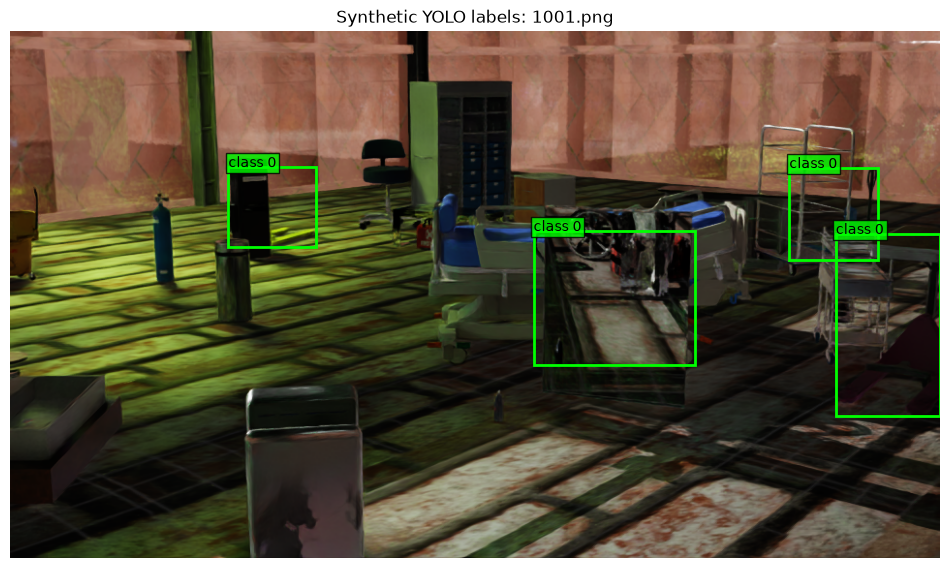

In [5]:
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


def show_synthetic_yolo_example(image_path, label_path):
    image = Image.open(image_path).convert("RGB")
    width, height = image.size
    figure, axis = plt.subplots(figsize=(12, 7))
    axis.imshow(image)
    axis.set_title(f"Synthetic YOLO labels: {Path(image_path).name}")
    axis.axis("off")

    label_path = Path(label_path)
    if label_path.exists():
        for line in label_path.read_text(encoding="utf-8").splitlines():
            fields = line.split()
            if len(fields) != 5:
                print(f"Skipping malformed YOLO label line: {line}")
                continue
            class_id, center_x, center_y, box_width, box_height = map(float, fields)
            left = (center_x - box_width / 2) * width
            top = (center_y - box_height / 2) * height
            axis.add_patch(Rectangle((left, top), box_width * width, box_height * height,
                                     fill=False, edgecolor="lime", linewidth=2))
            axis.text(left, top, f"class {int(class_id)}", color="black",
                      bbox={"facecolor": "lime", "alpha": 0.8, "pad": 2})
    else:
        axis.set_title(f"No matching YOLO label file: {label_path}")
    plt.show()


synthetic_image_root = SYNTHETIC_PROCESSED_ROOT / "images"
synthetic_label_root = SYNTHETIC_PROCESSED_ROOT / "labels"
synthetic_examples = sorted(synthetic_image_root.rglob("*")) if synthetic_image_root.exists() else []
synthetic_examples = [path for path in synthetic_examples if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}]
if synthetic_examples:
    example_image = synthetic_examples[0]
    relative_image = example_image.relative_to(synthetic_image_root)
    example_label = (synthetic_label_root / relative_image).with_suffix(".txt")
    show_synthetic_yolo_example(example_image, example_label)
else:
    print("No processed synthetic images found yet. Run the synthetic processing section to create examples.")

## Part 2 — prepare the real LOCO subset

The local LOCO source contains subset-1 JPGs and a COCO annotation file. The COCO categories include `pallet_truck`; for this project it maps to the single detector class `pallet-jack`.

We keep every image record present in COCO. When an image has no pallet-truck annotation, we remove its other-class boxes and leave it with an empty annotation list. This makes it a negative example for the pallet-jack class, not a second `none` class.

The folder has **65 JPGs that do not have image records in this COCO file**. Their labels are unknown, so the processing report lists them separately. They are not copied to the processed dataset and are not silently treated as negatives.


In [7]:
import json
from collections import Counter, defaultdict

if not LOCO_COCO_PATH.is_file():
    raise FileNotFoundError(f"LOCO COCO annotation file was not found: {LOCO_COCO_PATH}")
with LOCO_COCO_PATH.open(encoding="utf-8") as annotation_file:
    loco_source = json.load(annotation_file)

category_names = {category["id"]: category["name"] for category in loco_source["categories"]}
source_annotation_counts = Counter(annotation["category_id"] for annotation in loco_source["annotations"])
source_target_category_ids = {category_id for category_id, name in category_names.items() if name == "pallet_truck"}
source_target_image_ids = {
    annotation["image_id"] for annotation in loco_source["annotations"]
    if annotation["category_id"] in source_target_category_ids
}
raw_loco_images = {path.relative_to(LOCO_RAW_ROOT).as_posix() for path in LOCO_RAW_ROOT.rglob("*") if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png"}}
coco_image_paths = {record.get("path") or record.get("file_name") for record in loco_source["images"]}
unmatched_loco_images = sorted(raw_loco_images - coco_image_paths)
print(f"COCO image records: {len(loco_source['images'])}")
print(f"Source categories: {category_names}")
print(f"Source annotations: {len(loco_source['annotations'])}")
print(f"pallet_truck boxes: {sum(source_annotation_counts[cid] for cid in source_target_category_ids)}")
print(f"Images with pallet_truck boxes: {len(source_target_image_ids)}")
print(f"Images without pallet_truck boxes: {len(loco_source['images']) - len(source_target_image_ids)}")
print(f"Raw image files: {len(raw_loco_images)}")
print(f"Raw images lacking COCO image records: {len(unmatched_loco_images)}")
print("First unmatched filenames:", unmatched_loco_images[:10])

COCO image records: 1075
Source categories: {3: 'small_load_carrier', 5: 'forklift', 7: 'pallet', 10: 'stillage', 11: 'pallet_truck'}
Source annotations: 24763
pallet_truck boxes: 594
Images with pallet_truck boxes: 403
Images without pallet_truck boxes: 672
Raw image files: 1140
Raw images lacking COCO image records: 65
First unmatched filenames: ['subset-1/1564562461.5784624.jpg', 'subset-1/1564562467.6413686.jpg', 'subset-1/1564562740966,26.jpg', 'subset-1/1564562750962,62.jpg', 'subset-1/1564562759076,13.jpg', 'subset-1/1564562764.7535942.jpg', 'subset-1/1564562767.775108.jpg', 'subset-1/1564562769.8268123.jpg', 'subset-1/1564562774.9263299.jpg', 'subset-1/1564562775138,64.jpg']


### Preview the COCO transformation before copying files

The filtering function returns a new COCO object; it does not change the original JSON. It retains image records and their IDs, keeps only pallet-truck annotations, preserves annotation geometry/segmentation and metadata, and remaps the category to ID `1`, name `pallet-jack`.


In [9]:
loco_filtered_preview = filter_coco_to_pallet_jack(loco_source)
filtered_image_ids = {annotation["image_id"] for annotation in loco_filtered_preview["annotations"]}
print("Categories after filtering:", loco_filtered_preview["categories"])
print("Image records retained:", len(loco_filtered_preview["images"]))
print("Pallet-jack boxes retained:", len(loco_filtered_preview["annotations"]))
print("Images with pallet-jack boxes:", len(filtered_image_ids))
print("Negative images retained:", len(loco_filtered_preview["images"]) - len(filtered_image_ids))
print("Other-class annotations removed:", len(loco_source["annotations"]) - len(loco_filtered_preview["annotations"]))
print("Source COCO category count remains:", len(loco_source["categories"]))

Categories after filtering: [{'id': 1, 'name': 'pallet-jack', 'supercategory': '', 'color': '#6ba8dc', 'metadata': {}}]
Image records retained: 1075
Pallet-jack boxes retained: 594
Images with pallet-jack boxes: 403
Negative images retained: 672
Other-class annotations removed: 24169
Source COCO category count remains: 5


### Write the filtered LOCO dataset

This step copies only files listed in the COCO `images` array and writes `annotations.json` plus `processing_report.json` under the ignored processed-data folder. It is separate from synthetic training preparation. The script refuses to replace existing files unless they were generated by this processor and overwrite was explicitly enabled.

Set `RUN_REAL_DATA_PROCESSING = True` in the configuration cell to create or refresh the output. If you intend to replace a prior generated output, set `ALLOW_OVERWRITE_GENERATED = True` too.


In [10]:
if RUN_REAL_DATA_PROCESSING:
    loco_result = prepare_loco_pallet_jack_dataset(
        LOCO_COCO_PATH,
        LOCO_RAW_ROOT,
        LOCO_PROCESSED_ROOT,
        overwrite=ALLOW_OVERWRITE_GENERATED,
    )
    print(f"Copied COCO-listed images: {loco_result.copied_image_count}")
    print(f"Pallet-jack boxes: {loco_result.target_annotation_count}")
    print(f"Positive images: {loco_result.target_image_count}")
    print(f"Negative images: {loco_result.negative_image_count}")
    print(f"Unmatched raw image files: {len(loco_result.unmatched_image_files)}")
    print(f"Annotations: {loco_result.annotation_path}")
    print(f"Report: {loco_result.report_path}")
else:
    print("Real-data processing is off; no files were written.")
    if (LOCO_PROCESSED_ROOT / "annotations.json").is_file():
        print(f"Existing processed annotations: {LOCO_PROCESSED_ROOT / 'annotations.json'}")

Real-data processing is off; no files were written.
Existing processed annotations: c:\coding\RL\issac-sim-pallet-jack-perception\data\processed\real-pallet-jack-data\annotations.json


### Visual audit: before and after filtering

The two panels for a positive image show the same photo with (left) all original COCO classes and (right) only the retained pallet-jack box. A negative image demonstrates the intended result: other-class boxes disappear and the image remains with no target box. Inspect several images at different sizes and viewpoints before relying on the annotations for a quantitative real-world score.


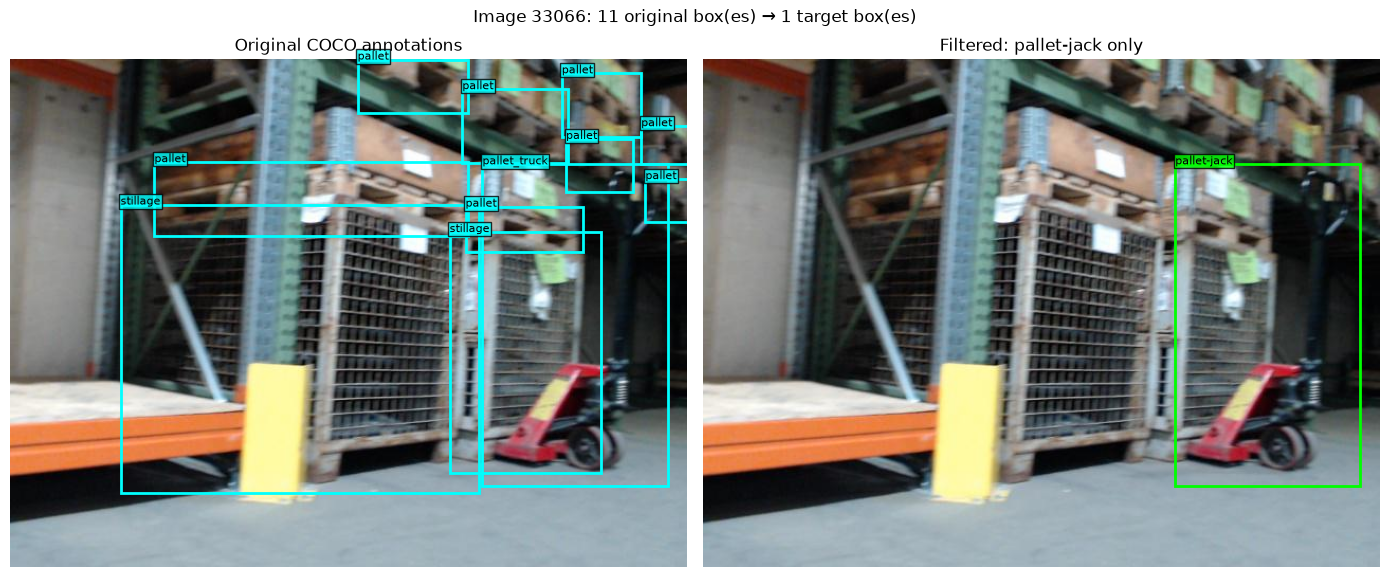

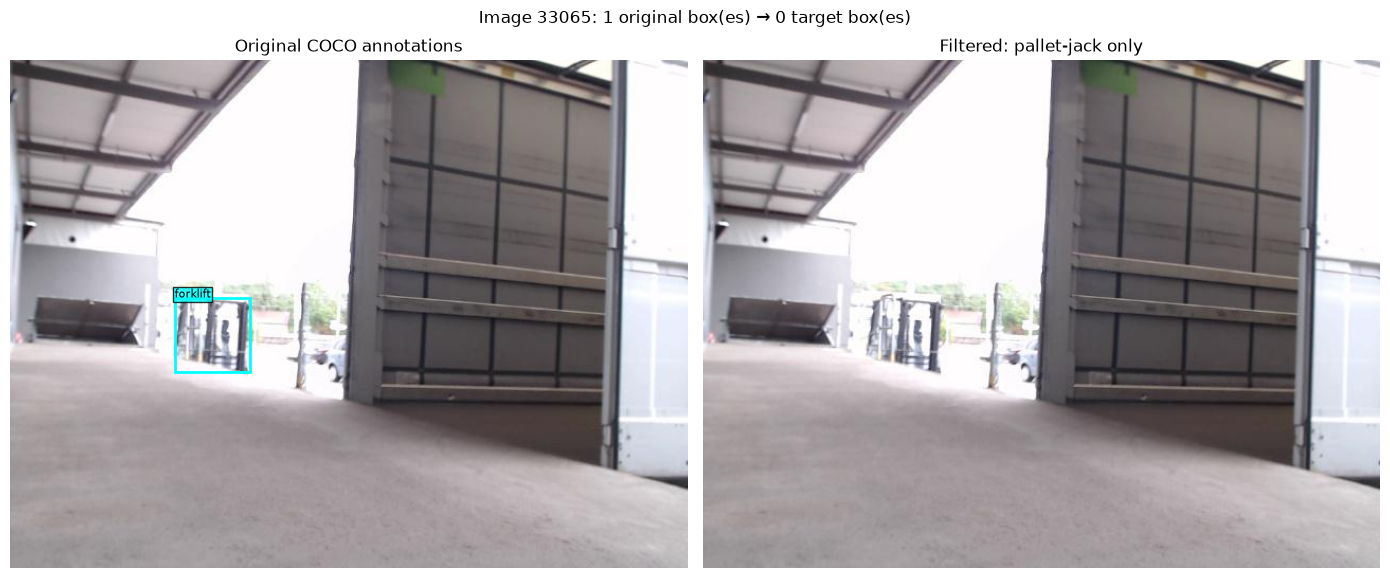

In [11]:
from matplotlib.patches import Rectangle


def _loco_image_path(image_root, image_record):
    relative_path = image_record.get("path") or image_record.get("file_name")
    return Path(image_root) / relative_path


def _draw_coco_image(axis, image_root, coco_data, image_record, title):
    image_path = _loco_image_path(image_root, image_record)
    if not image_path.is_file():
        raise FileNotFoundError(f"Image referenced by COCO was not found: {image_path}")
    image = Image.open(image_path).convert("RGB")
    axis.imshow(image)
    axis.set_title(title)
    axis.axis("off")
    category_by_id = {category["id"]: category["name"] for category in coco_data["categories"]}
    annotations = [item for item in coco_data["annotations"] if item["image_id"] == image_record["id"]]
    for annotation in annotations:
        x, y, box_width, box_height = annotation["bbox"]
        name = category_by_id[annotation["category_id"]]
        color = "lime" if name == "pallet-jack" else "cyan"
        axis.add_patch(Rectangle((x, y), box_width, box_height, fill=False, edgecolor=color, linewidth=2))
        axis.text(x, y, name, color="black", fontsize=8, bbox={"facecolor": color, "alpha": 0.8, "pad": 1})
    return len(annotations)


def show_loco_before_after(image_id):
    source_record = next(record for record in loco_source["images"] if record["id"] == image_id)
    figure, axes = plt.subplots(1, 2, figsize=(14, 6))
    source_count = _draw_coco_image(axes[0], LOCO_RAW_ROOT, loco_source, source_record, "Original COCO annotations")
    target_count = _draw_coco_image(axes[1], LOCO_RAW_ROOT, loco_filtered_preview, source_record, "Filtered: pallet-jack only")
    figure.suptitle(f"Image {image_id}: {source_count} original box(es) → {target_count} target box(es)")
    plt.tight_layout()
    plt.show()


loco_positive_id = next(annotation["image_id"] for annotation in loco_filtered_preview["annotations"])
loco_negative_id = next(record["id"] for record in loco_filtered_preview["images"] if record["id"] not in filtered_image_ids)
show_loco_before_after(loco_positive_id)
show_loco_before_after(loco_negative_id)

## Final review checklist

Before moving on to training or real-image evaluation, confirm:

- Synthetic validation passes and the split manifests contain each frame once.
- YOLO boxes appear over the correct synthetic pallet jacks; empty label files correspond to genuine negatives.
- The LOCO processed COCO file contains exactly one category named `pallet-jack` and retains all 1,075 COCO image records.
- A LOCO negative image remains in the processed set with no pallet-jack annotation.
- The 65 JPGs missing from the source COCO image records remain unscored until their labels are checked.
- Synthetic test metrics and real-image metrics are reported separately; this LOCO subset has not yet been independently audited as a benchmark.

**Next:** visually audit a representative set of LOCO boxes, then convert the reviewed real annotations to the model's evaluation format or use a COCO-capable evaluation workflow. Do not interpret a metric as trustworthy until annotation quality and split purpose are clear.
